# ✈️ TravelTide – Part 1: Data Cleaning & Exploratory Data Analysis

**Masterschool (MSIT) Data Analytics – Mastery Project**

### 🎯 Project Objective
The objective of this project is to support TravelTide's Head of Marketing, Elena Tarrant, in designing a personalized rewards program that boosts customer engagement and long-term retention.

TravelTide is a fast-growing online travel booking platform with strong search technology, but keeping customers coming back is a challenge. Using a relational database of customer profiles, session logs, flight bookings and hotel reservations, I analyze travel behavior, booking patterns and discount sensitivity. As the Data Analyst on this initiative, my goal is to translate the findings into actionable recommendations: distinct customer segments, each matched to the perk that fits it best.

### 📓 About this notebook
This notebook cleans and explores the session-level cohort table (one row = one browsing session). It is the foundation for Part 2 (user-level features and segmentation) and Part 3 (K-Means / DBSCAN and perk mapping).

**Cohort (Elena's brief):** sessions from 2023-01-04 onward, users with more than 7 sessions in that window → **49,211 sessions from 5,998 users**.

**How the data gets here**
1. SQL is written and tested in VS Code / Beekeeper (`sql/JT_session_and_user_base.sql`).
2. Query results are exported as CSV into the project's Google Drive `data` folder.
3. This notebook reads the CSVs from the local `data` folder, or directly from Google Drive if there is no local copy (works in Colab and VS Code).

**Notebook outline**
1. Setup & data loading
2. First inspection
3. Data cleaning (types, text formatting, missing values, hotel nights, cancellations, age)
4. Derived session/trip columns used later in the project
5. Exploratory data analysis
6. Export & key findings

## 1 – Setup & Data Loading

In [79]:
import importlib, importlib.util, subprocess, sys

# Install missing packages into THIS notebook's Python (sys.executable), so the notebook runs anywhere
# (Colab, VS Code venv, Jupyter). pip name → import name; plotly needs nbformat to draw maps in notebooks.
REQUIRED = {"pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib", "seaborn": "seaborn",
            "plotly": "plotly", "nbformat": "nbformat", "airports-py": "airports"}
missing = [pip_name for pip_name, module in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    importlib.invalidate_caches()   # make the new packages importable without a restart
    print("Installed:", ", ".join(missing))

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
PALETTE = ["#3D90F3",  # 0 brand blue – main bars, histograms, home-airport map
           "#A9CCF5",  # 1 pale blue – flat-signal charts, "no discount" pie slice
           "#2E7D8C",  # 2 ocean teal – 3rd gender group, destination map
           "#1B4F8A",  # 3 navy – spare
           "#0D0F14",  # 4 ink – dashed reference lines (age 18, 3,000 km, medians)
           "#79B7F6"]  # 5 light blue – spare
sns.set_palette(PALETTE)

def count_share(series, label=None, sort_index=False):
    """Absolute count and % share per value – shows where a percentage in the text comes from."""
    counts = series.value_counts()
    if sort_index:
        counts = counts.sort_index()
    out = counts.to_frame("count")
    out["share_%"] = (out["count"] / out["count"].sum() * 100).round(1)
    out.index.name = label or series.name
    return out

### 1.1 Load the CSV export (local folder first, Google Drive as fallback)

The shared Drive `data` folder contains all CSV files for our data analysis.

- **Local copy found** (VS Code repo, or Colab with Google Drive mounted) → the notebook reads it directly from there.
- **No local copy** → the notebook reads the file **straight from its Google Drive link** into memory. Nothing is downloaded or copied, so no duplicate `data` folders appear.

In [80]:
# *For the Drive fallback, each file is shared as "Anyone with the link – Viewer".*
# Shared project data folder on Google Drive (for reference / browsing):
# https://drive.google.com/drive/folders/13JVW64-U2woCIdmQ1KAQeTyiKwlwaJdc
DRIVE_FOLDER_ID = "13JVW64-U2woCIdmQ1KAQeTyiKwlwaJdc"

# Files used in this notebook: name in the data folder + Google Drive FILE ID
FILES = {
    "sessions": {"name": "session_level_table.csv", "drive_id": "1cZGmTakhtkm0vKJlguPk5H_Ea0SjjCyM"},
    "users":    {"name": "user_level_table.csv",       "drive_id": "1caT1H37JPzKNUo1EcM90eDIjHBe6nQG-"},   # used from Part 2 on
}

# Where the project data folder can be: repo root, notebooks/ subfolder, or Colab with Drive mounted
CANDIDATE_DIRS = [
    Path("data"),
    Path("../data"),
    Path("/content/drive/MyDrive/DS Mastery Project/data"),
]
DATA_DIR = next((d for d in CANDIDATE_DIRS if d.is_dir()), None)
print("Local data folder:", DATA_DIR.resolve() if DATA_DIR else "not found → reading from Google Drive")

def read_export(source):
    # na_values: the SQL export writes missing values as the text "NULL" → read them as real missing values (NaN)
    # encoding_errors: 2 airline names ("AeroMéxico", "Cubana de Aviación") are not UTF-8 encoded in the export;
    #   without this, reading crashes with a UnicodeDecodeError. The 2 names are repaired in 3.3.
    return pd.read_csv(source, na_values=["NULL"], encoding_errors="replace")

def load_table(key):
    name, drive_id = FILES[key]["name"], FILES[key]["drive_id"]
    if DATA_DIR is not None and (DATA_DIR / name).exists():
        print(f"{name}: read from local folder")
        return read_export(DATA_DIR / name)
    if not drive_id:
        raise FileNotFoundError(f"{name}: not in the local data folder and no Drive file ID set in FILES")
    print(f"{name}: read directly from Google Drive")
    return read_export(f"https://drive.google.com/uc?export=download&id={drive_id}")

sessions_raw = load_table("sessions")
df = sessions_raw.copy()   # working copy – sessions_raw stays untouched for before/after checks (3.1)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]} | Users: {df['user_id'].nunique():,}")

Local data folder: C:\Users\jackl\OneDrive\Attachments\Desktop\Masterschool\Mastery Project\TravelTide\data
session_level_table.csv: read from local folder
Rows: 49,211 | Columns: 42 | Users: 5,998


### 1.2 Optional: live queries against the TravelTide database

The analysis runs on the exported CSV. A live connection is only needed for checks the cohort export **cannot** answer – for example, how the gender split looked **before** the cohort filter. Set `RUN_LIVE_QUERIES = True` to run them.

Store the connection URL as a Colab secret or environment variable named `TRAVELTIDE_URL` (never commit it to GitHub). SQLAlchemy uses `psycopg2` underneath.

In [81]:
RUN_LIVE_QUERIES = False

if RUN_LIVE_QUERIES:
    import os
    if importlib.util.find_spec("psycopg2") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "psycopg2-binary"], check=True)
    from sqlalchemy import create_engine, text
    try:
        from google.colab import userdata
        db_url = userdata.get("TRAVELTIDE_URL")
    except ImportError:
        db_url = os.environ["TRAVELTIDE_URL"]
    engine = create_engine(db_url.replace("postgres://", "postgresql://", 1))

    gender_by_stage = pd.read_sql(text('''
        WITH active AS (SELECT DISTINCT user_id FROM sessions WHERE session_start >= '2023-01-04'),
             cohort AS (SELECT user_id FROM sessions WHERE session_start >= '2023-01-04'
                        GROUP BY user_id HAVING COUNT(*) > 7),
             stages AS (
                 SELECT '1 all users' AS stage, gender FROM users
                 UNION ALL SELECT '2 active since 2023-01-04', u.gender FROM users u JOIN active a USING (user_id)
                 UNION ALL SELECT '3 cohort (>7 sessions)',   u.gender FROM users u JOIN cohort c USING (user_id))
        SELECT stage, gender, COUNT(*) AS users,
               ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY stage), 1) AS pct
        FROM stages GROUP BY stage, gender ORDER BY stage, gender
    '''), engine)
    display(gender_by_stage)

### 1.3 First look: the four source tables inside the session table

The session-level table joins four database tables, which makes 42 columns at once. To keep it readable, the columns are grouped by their **source table** and each table is rebuilt from the session table:

- `users` → one row per user (`drop_duplicates` on `user_id`)
- `sessions` → one row per session (session columns only)
- `flights` / `hotels` → one row per booked trip that has a flight / hotel (`drop_duplicates` on `trip_id`)

This way only two CSV files are needed for the whole project (`session_level_table.csv`, `user_level_table.csv`). A check showed the rebuilt tables match the separate database exports exactly (5,998 users, 13,717 flights, 14,313 hotels).

In [82]:
# Which columns come from which database table
COLUMN_GROUPS = {
    "users": ["user_id", "birthdate", "gender", "married", "has_children", "home_country", "home_city",
              "home_airport", "home_airport_lat", "home_airport_lon", "sign_up_date"],
    "sessions": ["session_id", "user_id", "trip_id", "session_start", "session_end", "page_clicks",
                 "flight_discount", "flight_discount_amount", "flight_booked",
                 "hotel_discount", "hotel_discount_amount", "hotel_booked", "cancellation"],
    "flights": ["trip_id", "origin_airport", "destination", "destination_airport", "seats", "return_flight_booked",
                "departure_time", "return_time", "checked_bags", "trip_airline",
                "destination_airport_lat", "destination_airport_lon", "base_fare_usd"],
    "hotels": ["trip_id", "hotel_name", "nights", "rooms", "check_in_time", "check_out_time", "hotel_per_room_usd"],
}
# Every column belongs to a group (session_count is a helper from the SQL cohort step)
print("Columns not in a group:", set(df.columns) - set(sum(COLUMN_GROUPS.values(), [])))

df_users    = df[COLUMN_GROUPS["users"]].drop_duplicates("user_id")
df_sessions = df[COLUMN_GROUPS["sessions"]]
df_flights  = df.loc[df["destination"].notna(), COLUMN_GROUPS["flights"]].drop_duplicates("trip_id")
df_hotels   = df.loc[df["hotel_name"].notna(), COLUMN_GROUPS["hotels"]].drop_duplicates("trip_id")

tables = {"users": df_users, "sessions": df_sessions, "flights": df_flights, "hotels": df_hotels}
for name, table in tables.items():
    print(f"\n{name.upper()} – {table.shape[0]:,} rows × {table.shape[1]} columns")
    display(table.head())

Columns not in a group: {'session_count'}

USERS – 5,998 rows × 11 columns


,user_id,birthdate,gender,married,has_children,home_country,home_city,home_airport,home_airport_lat,home_airport_lon,sign_up_date
0,23557,1958-12-08,F,True,False,usa,new york,LGA,40.777,-73.872,2021-07-22
1,120851,1972-09-25,F,True,True,usa,santa ana,SNA,33.676,-117.868,2022-03-13
2,229108,1998-05-28,F,False,False,usa,burlington,BTV,44.472,-73.153,2022-06-27
3,264470,1978-11-05,F,False,True,usa,bakersfield,BFL,35.433,-119.057,2022-07-27
4,348863,1957-01-13,F,True,False,usa,san antonio,SKF,29.384,-98.581,2022-10-04



SESSIONS – 49,211 rows × 13 columns


,session_id,user_id,trip_id,session_start,session_end,page_clicks,flight_discount,flight_discount_amount,flight_booked,hotel_discount,hotel_discount_amount,hotel_booked,cancellation
0,23557-3f6bd6be250e45959b33b808ac525df6,23557,NaN,2023-01-04 19:30:00,2023-01-04 19:33:53,32,False,NaN,False,False,NaN,False,False
1,120851-bfeb515377f44fdbbb9d9642dc0c7178,120851,NaN,2023-01-04 19:49:00,2023-01-04 19:49:37,5,False,NaN,False,False,NaN,False,False
2,229108-d2b0f9bc7aea425189cb943fa1706810,229108,NaN,2023-01-04 20:44:00,2023-01-04 20:45:29,12,True,0.2,False,False,NaN,False,False
3,264470-71e8f4d269aa44308aa34ffd1c2d0c18,264470,NaN,2023-01-04 22:50:00,2023-01-04 22:50:59,8,False,NaN,False,False,NaN,False,False
4,348863-e3c9ba813fc84210a236a3a11e364859,348863,NaN,2023-01-04 08:57:00,2023-01-04 08:58:15,10,False,NaN,False,False,NaN,False,False



FLIGHTS – 13,717 rows × 13 columns


,trip_id,origin_airport,destination,destination_airport,seats,return_flight_booked,departure_time,return_time,checked_bags,trip_airline,destination_airport_lat,destination_airport_lon,base_fare_usd
155,510365-edd2f605ca324ff78cbe5cc1236b6ea7,BOS,toronto,YTZ,3.0,True,2023-01-09 14:00:00,2023-01-24 14:00:00,0.0,Porter Airlines,43.862,-79.370,379.11
353,512201-d198cb30dbe945a58808812558288792,SJC,new york,LGA,1.0,True,2023-01-14 11:00:00,2023-01-23 11:00:00,1.0,United Airlines,40.640,-73.779,781.52
423,476714-f7d36ece6b46409cbe363123d363bd40,CMH,oklahoma city,OKC,2.0,True,2023-01-15 08:00:00,2023-01-16 08:00:00,1.0,Virgin Atlantic Airways,35.393,-97.601,512.76
756,515243-5a7e18c70ef64fc1b221ab42bb7b1197,HNL,las vegas,LSV,2.0,True,2023-01-14 07:00:00,2023-01-19 07:00:00,1.0,United Airlines,36.080,-115.152,1790.49
919,515398-1eecb60b58b24615b7a8a23595c98f58,LGA,los angeles,LSQ,2.0,True,2023-01-13 07:00:00,2023-01-14 07:00:00,1.0,United Airlines,33.942,-118.408,1651.04



HOTELS – 14,313 rows × 7 columns


,trip_id,hotel_name,nights,rooms,check_in_time,check_out_time,hotel_per_room_usd
155,510365-edd2f605ca324ff78cbe5cc1236b6ea7,Choice Hotels - toronto,12.0,3.0,2023-01-09 16:52:24.6,2023-01-22 11:00:00,168.0
353,512201-d198cb30dbe945a58808812558288792,Shangri-La - new york,8.0,1.0,2023-01-14 18:09:21.555,2023-01-23 11:00:00,171.0
423,476714-f7d36ece6b46409cbe363123d363bd40,Banyan Tree - oklahoma city,0.0,2.0,2023-01-15 11:44:13.425,2023-01-15 11:00:00,294.0
975,517491-f17c9a923a054db2955c3f56a7d8486e,Banyan Tree - fort worth,3.0,1.0,2023-01-13 10:18:23.85,2023-01-16 11:00:00,154.0
989,517735-a543e7016da749e09ee511d199f6f3dc,Fairmont - jacksonville,6.0,2.0,2023-01-13 10:09:21.96,2023-01-19 11:00:00,247.0


In [83]:
table_info = {
    "users":    ("dimension", "one row per user",                 "user_id"),
    "sessions": ("fact",      "one row per browsing session",     "session_id"),
    "flights":  ("fact",      "one row per booked flight (trip)", "trip_id"),
    "hotels":   ("fact",      "one row per booked hotel (trip)",  "trip_id"),
}
overview = pd.DataFrame([
    {"table": name, "type": kind, "grain": grain, "key": key,
     "rows": len(tables[name]), "columns": tables[name].shape[1], "key_unique": tables[name][key].is_unique}
    for name, (kind, grain, key) in table_info.items()
])
display(overview)
print("Trips with flight AND hotel:", len(set(df_flights["trip_id"]) & set(df_hotels["trip_id"])))

,table,type,grain,key,rows,columns,key_unique
0,users,dimension,one row per user,user_id,5998,11,True
1,sessions,fact,one row per browsing session,session_id,49211,13,True
2,flights,fact,one row per booked flight (trip),trip_id,13717,13,True
3,hotels,fact,one row per booked hotel (trip),trip_id,14313,7,True


Trips with flight AND hotel: 11931


**How the tables connect**

![TravelTide database schema](images/TravelTide_ERD.png)

- `users` is the **dimension** table (who the customer is); `sessions`, `flights` and `hotels` are **fact** tables (what happened).
- One user has many sessions; a session has a `trip_id` only if something was booked (or cancelled).
- A trip can have a flight, a hotel, or both – that's why flights and hotels are joined with **LEFT JOINs** in the SQL, so browsing sessions are kept.
- `df_users`, `df_flights` etc. are handy for a quick look at one table; the cleaning below works on the full joined table `df`.

## 2 – First Inspection

In [84]:
df.head(5).T

,0,1,2,3,4
session_id,23557-3f6bd6be250e45959b33b808ac525df6,120851-bfeb515377f44fdbbb9d9642dc0c7178,229108-d2b0f9bc7aea425189cb943fa1706810,264470-71e8f4d269aa44308aa34ffd1c2d0c18,348863-e3c9ba813fc84210a236a3a11e364859
user_id,23557,120851,229108,264470,348863
trip_id,NaN,NaN,NaN,NaN,NaN
session_start,2023-01-04 19:30:00,2023-01-04 19:49:00,2023-01-04 20:44:00,2023-01-04 22:50:00,2023-01-04 08:57:00
session_end,2023-01-04 19:33:53,2023-01-04 19:49:37,2023-01-04 20:45:29,2023-01-04 22:50:59,2023-01-04 08:58:15
page_clicks,32,5,12,8,10
flight_discount,False,False,True,False,False
flight_discount_amount,NaN,NaN,0.2,NaN,NaN
flight_booked,False,False,False,False,False
hotel_discount,False,False,False,False,False


In [85]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49211 entries, 0 to 49210
Data columns (total 42 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   session_id               49211 non-null  str    
 1   user_id                  49211 non-null  int64  
 2   trip_id                  16702 non-null  str    
 3   session_start            49211 non-null  str    
 4   session_end              49211 non-null  str    
 5   page_clicks              49211 non-null  int64  
 6   flight_discount          49211 non-null  bool   
 7   flight_discount_amount   8282 non-null   float64
 8   flight_booked            49211 non-null  bool   
 9   hotel_discount           49211 non-null  bool   
 10  hotel_discount_amount    6205 non-null   float64
 11  hotel_booked             49211 non-null  bool   
 12  cancellation             49211 non-null  bool   
 13  session_count            49211 non-null  int64  
 14  birthdate                49211 no

In [86]:
# Cohort sanity checks: every user must have at least 8 sessions, all sessions inside the window
print("Min sessions per user:", df.groupby("user_id")["session_id"].count().min())
print("Session window:", df["session_start"].min(), "→", df["session_end"].max())
print("Duplicate session_ids:", df["session_id"].duplicated().sum(), "| Fully duplicated rows:", df.duplicated().sum())

Min sessions per user: 8
Session window: 2023-01-04 00:01:00 → 2023-07-28 20:08:52
Duplicate session_ids: 0 | Fully duplicated rows: 0


**Observations:** 42 columns from four joined tables. Dates are stored as text, several integer columns are floats (because of missing values), and text columns use mixed casing. There are no duplicate sessions, and every user has at least 8 sessions, so the cohort filter worked as intended.

## 3 – Data Cleaning

**Guiding rule:** no session rows are dropped. Removing rows would change the cohort (users could fall below 8 sessions) and break the link to Elena's definition. Problems are fixed or flagged instead.

### 3.1 Date and time columns

In [87]:
datetime_cols = ["session_start", "session_end", "departure_time", "return_time", "check_in_time", "check_out_time"]
date_cols = ["birthdate", "sign_up_date"]

# ISO8601 handles mixed precision (some check-in times carry microseconds)
for col in datetime_cols:
    df[col] = pd.to_datetime(df[col], format="ISO8601")
for col in date_cols:
    df[col] = pd.to_datetime(df[col], format="%Y-%m-%d")

print("Unparsed values:", df[datetime_cols + date_cols].isna().sum().sum() - sessions_raw[datetime_cols + date_cols].isna().sum().sum())
print("session_end before session_start:", (df["session_end"] < df["session_start"]).sum())
print("return before departure:", (df["return_time"] < df["departure_time"]).sum())

Unparsed values: 0
session_end before session_start: 0
return before departure: 0


### 3.2 Integer and boolean columns

`seats`, `checked_bags`, `rooms` and `nights` are counts, but pandas reads them as floats because sessions without a flight or hotel have no value. They become **nullable integers (`Int64`)** – missing stays missing.

> Filling them with 0 would be wrong: a browsing session did not book "0 seats", it booked no flight at all. Zeros would pull every average down.

In [88]:
count_cols = ["seats", "checked_bags", "rooms", "nights"]
df[count_cols] = df[count_cols].astype("Int64")
df[count_cols].dtypes

seats           Int64
checked_bags    Int64
rooms           Int64
nights          Int64
dtype: object

`return_flight_booked` only applies to sessions with a flight. It is missing for all 34,891 sessions without a flight (correct) and for 50 flight sessions. Those 50 also have no `return_time`, so they are one-way flights → `False`. The column becomes a nullable boolean so "no flight" stays missing.

> Careful: `astype(bool)` on a column with `NaN` turns every `NaN` into `True`.

In [89]:
print(pd.crosstab(df["flight_booked"], df["return_flight_booked"], dropna=False))
one_way = df["flight_booked"] & df["return_flight_booked"].isna()
print("Flight sessions without return info:", one_way.sum(), "| of these with a return_time:", df.loc[one_way, "return_time"].notna().sum())

df["return_flight_booked"] = df["return_flight_booked"].astype("boolean")
df.loc[one_way, "return_flight_booked"] = False
df["return_flight_booked"].value_counts(dropna=False)

return_flight_booked  False   True    NaN
flight_booked                            
False                     0      0  34891
True                    618  13652     50
Flight sessions without return info: 50 | of these with a return_time: 0


return_flight_booked
<NA>     34891
True     13652
False      668
Name: count, dtype: Int64

### 3.3 Text formatting and unused columns

Text values are standardized for readable tables and charts (Tableau, Streamlit, slides):

| Column | Rule | Example |
|---|---|---|
| `home_country` | country name | `usa` → `USA`, `canada` → `Canada` |
| `home_city`, `destination` | Title Case (apostrophes stay lower case) | `new york` → `New York`, `xi'an` → `Xi'an` |
| airport codes | upper case | `lga` → `LGA` |
| `hotel_name` | Title Case, double spaces removed, **brand and city kept** | `Banyan Tree  - oklahoma city` → `Banyan Tree - Oklahoma City` |
| `hotel_city` (new) | city part of `hotel_name` | `Oklahoma City` |
| `trip_airline` | 2 names repaired (not UTF-8 in the export, see 1.1) | `AeroM�xico` → `AeroMéxico` |
| `gender` | kept as `F` / `M` / `O` | – |

**Why the hotel city stays in the name:** one chain runs hotels in many cities (957 hotels from only 20 chains). Shortening the name to the brand would merge e.g. all Accor hotels into one. The city is also the **only location of hotel-only trips** – they have no flight `destination`.

**Kept, but not used for segmentation:** `origin_airport` (identical to `home_airport` for 99.7 % of flights) and `trip_airline` (airlines play no role in the perks). They cost almost no memory and keep the cleaned table complete, e.g. for Tableau tooltips.

In [90]:
print("origin_airport == home_airport:", round((df.loc[df["flight_booked"], "origin_airport"] == df.loc[df["flight_booked"], "home_airport"]).mean() * 100, 1), "%")

def title_case(s):
    # Title Case every word; letters after an apostrophe stay lower case ("Xi'an", not "Xi'An")
    return s.str.strip().str.title().str.replace(r"'(\w)", lambda m: "'" + m[1].lower(), regex=True)

for col in ["home_city", "destination"]:
    df[col] = title_case(df[col])
for col in ["home_airport", "origin_airport", "destination_airport"]:
    df[col] = df[col].str.strip().str.upper()
df["home_country"] = df["home_country"].str.strip().map({"usa": "USA", "canada": "Canada"})
df["gender"] = df["gender"].str.strip().str.upper()

# hotel_name = "Brand - City": keep both parts, fix 2 brand spellings that Title Case gets wrong
df["hotel_name"] = (title_case(df["hotel_name"].str.replace(r"\s+", " ", regex=True))
                    .replace({r"^Nh Hotel": "NH Hotel", r"^Intercontinental": "InterContinental"}, regex=True))
df["hotel_city"] = df["hotel_name"].str.split(" - ").str[-1]

# repair the 2 airline names that were not UTF-8 encoded in the export (see 1.1)
df["trip_airline"] = df["trip_airline"].replace({"AeroM\ufffdxico": "AeroMéxico", "Cubana de Aviaci\ufffdn": "Cubana de Aviación"})

# check: hotel city vs flight destination on package trips (flight + hotel, not cancelled)
package = df["flight_booked"] & df["hotel_booked"] & ~df["cancellation"]
print("hotel_city == destination (package sessions):", round((df.loc[package, "hotel_city"] == df.loc[package, "destination"]).mean() * 100, 1), "%")
print(f"Hotels: {df['hotel_name'].nunique()} from {df['hotel_name'].str.split(' - ').str[0].nunique()} chains")
df[["home_country", "home_city", "home_airport", "destination", "destination_airport", "hotel_name", "hotel_city", "trip_airline"]].dropna().head()

origin_airport == home_airport: 99.7 %
hotel_city == destination (package sessions): 100.0 %
Hotels: 957 from 20 chains


,home_country,home_city,home_airport,destination,destination_airport,hotel_name,hotel_city,trip_airline
155,USA,Boston,BOS,Toronto,YTZ,Choice Hotels - Toronto,Toronto,Porter Airlines
353,USA,San Jose,SJC,New York,LGA,Shangri-La - New York,New York,United Airlines
423,USA,Columbus,CMH,Oklahoma City,OKC,Banyan Tree - Oklahoma City,Oklahoma City,Virgin Atlantic Airways
975,USA,Nashville,BNA,Fort Worth,FTW,Banyan Tree - Fort Worth,Fort Worth,American Airlines
989,USA,Memphis,MEM,Jacksonville,NZC,Fairmont - Jacksonville,Jacksonville,American Airlines


In [91]:
user_first = df.groupby("user_id")[["gender", "home_country"]].first()
display(pd.concat({col: count_share(user_first[col]) for col in ["gender", "home_country"]}, names=["column", "value"]))
print("Destinations:", df["destination"].nunique(), "| Home cities:", df["home_city"].nunique())

count  share_%
column       value                 
gender       F        5292     88.2
             M         695     11.6
             O          11      0.2
home_country USA      4991     83.2
             Canada   1007     16.8

Destinations: 125 | Home cities: 105


**Gender** (table above): 88 % of cohort users are female (5,292 of 5,998), 12 % male (695) and 11 users (0.2 %) `O`. The `O` users are **kept**: dropping them would remove sessions from the cohort, and gender is not used as a segmentation feature. The strong female majority is a property of the *filtered* cohort – see the live check in 1.2 for the split before filtering.

#### Full airport names

Airport codes like `TCM` or `BIF` are hard to read in tables and charts. The `airports-py` package looks up the full name and type of each IATA code. Two codes are missing from the package because the airports are closed (Berlin Schönefeld `SXF`, Berlin Tempelhof `THF`), so their names are added by hand.

In [92]:
from airports import airport_data

CLOSED_AIRPORTS = {"SXF": "Berlin Schönefeld Airport (closed)", "THF": "Berlin Tempelhof Airport (closed)"}

def airport_info(code):
    hits = airport_data.get_airport_by_iata(code)
    if hits:
        return {"airport_code": code, "airport_name": hits[0]["airport"], "airport_type": hits[0]["type"],
                "scheduled_service": str(hits[0]["scheduled_service"]).upper() == "TRUE", "country_code": hits[0]["country_code"]}
    return {"airport_code": code, "airport_name": CLOSED_AIRPORTS.get(code, "Not found"),
            "airport_type": "closed", "scheduled_service": False, "country_code": None}

codes = sorted(set(df["home_airport"].dropna()) | set(df["destination_airport"].dropna()))
airport_lookup = pd.DataFrame([airport_info(c) for c in codes])

# Add the full names to the session table (useful for Tableau tooltips and readable tables)
names = airport_lookup.set_index("airport_code")["airport_name"]
df["home_airport_name"] = df["home_airport"].map(names)
df["destination_airport_name"] = df["destination_airport"].map(names)

# Lookup table: how often each airport is a home airport (users) or a destination (flights)
home_users = df.groupby("home_airport")["user_id"].nunique().rename("home_users")
dest_flights = df[df["flight_booked"] & ~df["cancellation"]].groupby("destination_airport")["session_id"].count().rename("destination_flights")
airport_lookup = (airport_lookup.set_index("airport_code")
                  .join([home_users, dest_flights]).fillna({"home_users": 0, "destination_flights": 0})
                  .astype({"home_users": int, "destination_flights": int})
                  .sort_values("home_users", ascending=False))
print(f"{len(airport_lookup)} airports | home airports: {(airport_lookup['home_users'] > 0).sum()} | destinations: {(airport_lookup['destination_flights'] > 0).sum()}")
airport_lookup.head(15)

261 airports | home airports: 159 | destinations: 183


,airport_name,airport_type,scheduled_service,country_code,home_users,destination_flights
airport_code,,,,,,
LGA,LaGuardia Airport,large_airport,True,US,362,959
LAX,Los Angeles International Airport,large_airport,True,US,325,492
JFK,John F. Kennedy International Airport,large_airport,True,US,318,987
DAL,Dallas Love Field,large_airport,True,US,117,367
YYC,Calgary International Airport,large_airport,True,CA,101,343
SFO,San Francisco International Airport,large_airport,True,US,80,242
AUS,Austin-Bergstrom International Airport,large_airport,True,US,78,247
SJC,Norman Y. Mineta San Jose International Airport,large_airport,True,US,75,101
BNA,Nashville International Airport,large_airport,True,US,74,166


In [93]:
# Home airports that are not regular passenger airports (military bases, small fields)
unusual = airport_lookup[(airport_lookup["home_users"] > 0) &
                         ((airport_lookup["airport_type"] != "large_airport") | (~airport_lookup["scheduled_service"]))]
print(f"Home airports that are not large scheduled airports: {len(unusual)} "
      f"({unusual['home_users'].sum()} users, {unusual['home_users'].sum() / df['user_id'].nunique():.1%})")
unusual[["airport_name", "airport_type", "scheduled_service", "home_users"]].head(15)

Home airports that are not large scheduled airports: 66 (1643 users, 27.4%)


,airport_name,airport_type,scheduled_service,home_users
airport_code,,,,
YKZ,Buttonville Municipal Airport,medium_airport,False,66
YMX,Mirabel International Airport,medium_airport,False,64
UGN,Waukegan National Airport,small_airport,False,61
LUF,Luke Air Force Base,medium_airport,False,60
YZD,Downsview Airport,small_airport,False,53
LOU,Bowman Field,medium_airport,False,53
PNE,North Philadelphia Airport,medium_airport,False,51
NZY,North Island Naval Air Station,medium_airport,False,50
FTW,Fort Worth Meacham International Airport,medium_airport,False,50


**Data note:** about 27 % of users (1,643 of 5,998, printed above) have a home airport that is not a large airport with scheduled flights – some are even military bases (e.g. `TCM` McChord Air Force Base for Tacoma, `LUF` Luke Air Force Base for Phoenix, `NZY` North Island Naval Air Station for San Diego). The dataset seems to assign each home city an airport code nearby, not the airport people really fly from. Airport names are therefore used for readability only, and distances are calculated between coordinates – which stay valid either way.

**Same name, different city:** three home city names stand for two different cities each – Portland (Oregon `PDX` / Maine `PWM`), Jacksonville and Fayetteville. Wherever users are grouped by home location (e.g. the map in 5.7), the airport code is used as well, so they are not merged. Destination names are safe: all airports with the same destination name lie within 150 km of each other (same metro area).

### 3.4 Missing values: structural or a problem?

Missing values in this table are expected when they belong to something that was not booked. The check below confirms that every gap is explained by the booking flags.

In [94]:
flight_cols = ["origin_airport", "destination", "destination_airport", "destination_airport_name", "seats", "checked_bags", "departure_time", "trip_airline",
               "destination_airport_lat", "destination_airport_lon", "base_fare_usd"]
hotel_cols = ["hotel_name", "hotel_city", "nights", "rooms", "check_in_time", "check_out_time", "hotel_per_room_usd"]

# Expected reason for a gap in each column group
expected_gap = {
    **{c: ~df["flight_booked"] | df["cancellation"] for c in flight_cols},
    **{c: ~df["hotel_booked"] | df["cancellation"] for c in hotel_cols},
    "return_time": ~df["flight_booked"] | df["cancellation"] | (df["return_flight_booked"] == False),
    "return_flight_booked": ~df["flight_booked"],
    "flight_discount_amount": ~df["flight_discount"] | df["cancellation"],
    "hotel_discount_amount": ~df["hotel_discount"] | df["cancellation"],
    "trip_id": ~df["flight_booked"] & ~df["hotel_booked"],
}
checks = df.isna().sum().to_frame("missing_total").query("missing_total > 0")
checks["missing_%"] = (checks["missing_total"] / len(df) * 100).round(1)
checks["explained"] = [(df[c].isna() & expected_gap[c]).sum() for c in checks.index]
checks["unexplained"] = checks["missing_total"] - checks["explained"]
checks.sort_values("missing_total", ascending=False)

,missing_total,missing_%,explained,unexplained
hotel_discount_amount,43006,87.4,43006,0
flight_discount_amount,40929,83.2,40929,0
return_time,35559,72.3,35559,0
destination_airport,34941,71.0,34941,0
destination,34941,71.0,34941,0
seats,34941,71.0,34941,0
origin_airport,34941,71.0,34941,0
destination_airport_lon,34941,71.0,34941,0
departure_time,34941,71.0,34941,0
checked_bags,34941,71.0,34941,0


- **Flight and hotel columns:** missing when no flight / hotel was booked → structural, no imputation. The few extra gaps (50 flight, 193 hotel) are all on **cancellation sessions**, which repeat the booking flags but not always the trip details – they are excluded from travel behavior anyway (3.6).
- **`return_time`:** additionally missing for the 668 one-way flights → correct.
- **`trip_id`:** missing for the 32,509 browsing-only sessions → correct.
- **Discount amounts:** missing when no discount was offered. 610 sessions have a discount flag but no amount – these are exactly the cancellation sessions (see 3.6). Note: a discount *flag* on a browsing session means a discount was **offered**, not used; "discount used" is only measured on booked trips (section 4).

In [95]:
print("Discount flag without amount:", (df["flight_discount"] & df["flight_discount_amount"].isna()).sum(),
      "| all on cancellation sessions:", (df["flight_discount"] & df["flight_discount_amount"].isna() & df["cancellation"]).sum())
print("Flight discounts offered in sessions without a flight booking:",
      (df["flight_discount"] & ~df["flight_booked"]).sum(), "of", df["flight_discount"].sum())

Discount flag without amount: 610 | all on cancellation sessions: 610
Flight discounts offered in sessions without a flight booking: 6312 of 8892


### 3.5 Hotel nights

The raw `nights` column contains negative values and often disagrees with the check-in/check-out dates. Comparing it with the **calendar nights** (check-out date minus check-in date) shows the pattern: raw `nights` counts full 24-hour periods, so a stay from 14:47 to 11:00 the next morning shows 0 nights instead of 1.

**Decision:** use calendar nights (`nights_calc`). Stays with 0 or negative calendar nights (check-out on or before check-in) are invalid hotel dates → `nights_calc` is set to missing and flagged, the session itself is kept.

In [96]:
calendar_nights = (df["check_out_time"].dt.normalize() - df["check_in_time"].dt.normalize()).dt.days
print(pd.crosstab(df["nights"].clip(-2, 4), calendar_nights.clip(-2, 4), rownames=["raw nights"], colnames=["calendar nights"]))

df["invalid_hotel_dates"] = calendar_nights.le(0) & df["hotel_booked"]
df["nights_calc"] = calendar_nights.where(calendar_nights > 0).astype("Int64")
print("\nRaw nights < 0:", (df["nights"] < 0).sum(),
      "| raw ≠ calendar:", (df["nights"] != calendar_nights)[df["hotel_booked"]].sum(),
      "| invalid hotel dates:", df["invalid_hotel_dates"].sum(),
      f"({df['invalid_hotel_dates'].sum() / df['hotel_booked'].sum():.1%} of hotel sessions)")
df = df.drop(columns="nights")

calendar nights  -1.0   0.0   1.0   2.0   3.0   4.0
raw nights                                         
-2                  1     0     0     0     0     0
-1                 26    80     0     0     0     0
0                   0   332   896     0     0     0
1                   0     0   908  2297     0     0
2                   0     0     0   921  1931     0
3                   0     0     0     0   703  1301
4                   0     0     0     0     0  5330

Raw nights < 0: 107 | raw ≠ calendar: 8848 | invalid hotel dates: 439 (2.9% of hotel sessions)


### 3.6 Cancellations

A cancellation is recorded as a **second session with the same `trip_id`** (`cancellation = True`, booking flags repeated). Counting both sessions would double-count the trip, and counting the original booking would treat a cancelled trip as travel.

**Decision:** flag every session whose trip was later cancelled (`trip_cancelled`). A **valid booking** is a booking session whose trip was never cancelled.

In [97]:
cancelled_ids = set(df.loc[df["cancellation"], "trip_id"])
df["trip_cancelled"] = df["trip_id"].isin(cancelled_ids)
df["valid_booking"] = df["trip_id"].notna() & ~df["cancellation"] & ~df["trip_cancelled"]

print("Cancellation sessions:", df["cancellation"].sum(), "| cancelled trips:", len(cancelled_ids))
print("Sessions with a trip_id:", df["trip_id"].notna().sum(), "| unique trips:", df["trip_id"].nunique())
print("Valid (kept) bookings:", df["valid_booking"].sum())
print("Users without any valid booking:", (~df.groupby("user_id")["valid_booking"].any()).sum())

Cancellation sessions: 610 | cancelled trips: 610
Sessions with a trip_id: 16702 | unique trips: 16099
Valid (kept) bookings: 15489
Users without any valid booking: 556


### 3.7 Age and account tenure

**Which date to measure age at?** All behavior in the cohort happens between 2023-01-04 and 2023-07-28. Age is a user attribute used at user level, so every user needs **one** age:

- **Reference date = last session end in the data (2023-07-28)** ✅ – same reference for everyone, works for the 556 users who never booked, results don't change when the notebook is re-run later.
- Today's date ❌ – adds 3+ years to everyone and changes every time the notebook runs.
- Age at each booking or trip ❌ – differs from the reference age by at most 7 months, is missing for non-bookers and gives several ages per user.

Age is computed in exact years (birthday reached or not), not `days // 365`, which drifts with leap years.

In [98]:
REF_DATE = df["session_end"].max().normalize()
print("Reference date:", REF_DATE.date())

def age_on(birth, ref):
    # Exact age in full years: subtract one if the birthday hasn't happened yet in the reference year
    before_birthday = (birth.dt.month > ref.month) | ((birth.dt.month == ref.month) & (birth.dt.day > ref.day))
    return (ref.year - birth.dt.year - before_birthday.astype(int)).astype("Int64")

df["age"] = age_on(df["birthdate"], REF_DATE)
df["tenure_months"] = ((REF_DATE - df["sign_up_date"]).dt.days / 30.44).round(1)

users = df.groupby("user_id")[["age", "tenure_months"]].first()
print(users.describe().round(1))
n_minor = (users["age"] < 18).sum()
print(f"\nUsers under 18 on the reference date: {n_minor} of {len(users):,} ({n_minor / len(users):.1%})")

Reference date: 2023-07-28
          age  tenure_months
count  5998.0         5998.0
mean     40.9            6.2
std      12.0            1.2
min      16.0            2.3
25%      34.0            5.7
50%      41.0            6.2
75%      48.0            6.6
max      88.0           24.2

Users under 18 on the reference date: 246 of 5,998 (4.1%)


**Data note:** 246 of 5,998 cohort users (4.1 %) are under 18 on the reference date (youngest: 16). They are **kept** – they are real active accounts – but flagged with `is_minor`. Recommendation for TravelTide: check the sign-up age rules; for the rewards program, perks for these users may need a guardian or adult account.

In [99]:
df["is_minor"] = df["age"] < 18
df = df.drop(columns=["birthdate", "sign_up_date"])

### 3.8 Outliers

In [100]:
outlier_cols = ["page_clicks", "base_fare_usd", "hotel_per_room_usd", "seats", "checked_bags", "rooms", "nights_calc"]

def iqr_summary(s):
    q1, q3 = s.quantile([.25, .75]); upper = q3 + 1.5 * (q3 - q1)
    return pd.Series({"median": s.median(), "q3": q3, "upper_fence": upper, "max": s.max(),
                      "share_above_fence_%": round((s > upper).mean() * 100, 1)})

pd.DataFrame({c: iqr_summary(df[c].dropna().astype(float)) for c in outlier_cols}).T.round(1)

,median,q3,upper_fence,max,share_above_fence_%
page_clicks,13.0,22.0,46.0,566.0,4.3
base_fare_usd,381.8,600.6,1200.9,21548.0,6.1
hotel_per_room_usd,148.0,222.0,406.5,1376.0,4.6
seats,1.0,1.0,1.0,8.0,15.5
checked_bags,1.0,1.0,2.5,8.0,1.2
rooms,1.0,1.0,1.0,4.0,15.5
nights_calc,3.0,5.0,9.5,43.0,8.7


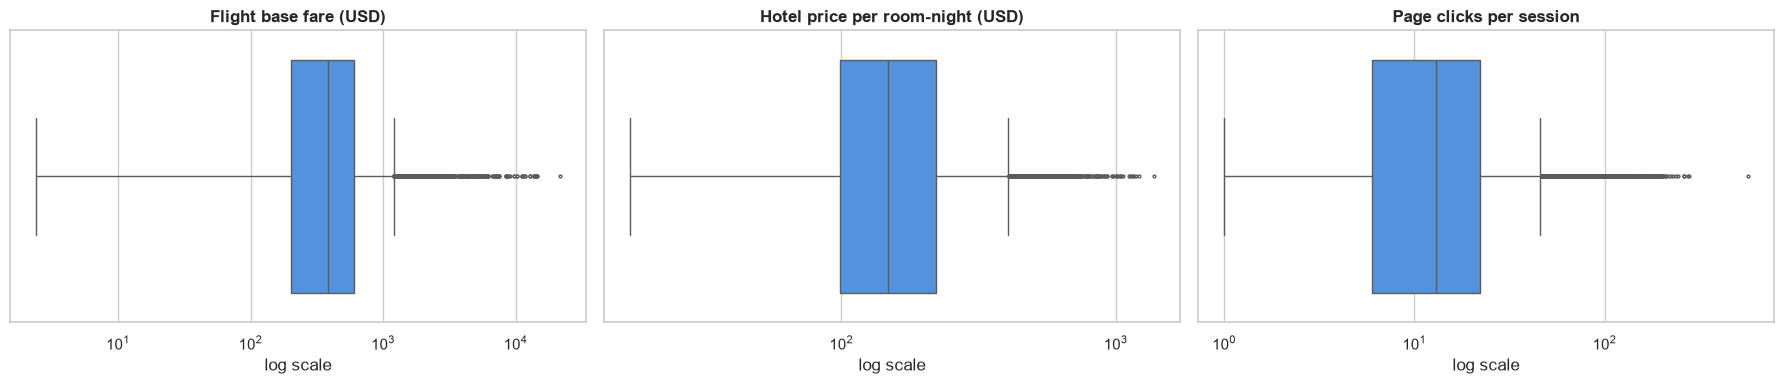

In [101]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col, title in zip(axes, ["base_fare_usd", "hotel_per_room_usd", "page_clicks"],
                          ["Flight base fare (USD)", "Hotel price per room-night (USD)", "Page clicks per session"]):
    sns.boxplot(x=df[col].dropna(), ax=ax, color=PALETTE[0], fliersize=2)
    ax.set_xscale("log"); ax.set_title(title, fontweight="bold"); ax.set_xlabel("log scale")
plt.tight_layout(); plt.show()

**Decision:** outliers are **kept**. They are plausible (long-haul business fares, luxury hotels, long research sessions) and some segments are defined by exactly these extremes (e.g. Long-haul Packers). Skewed features are log-transformed and scaled before clustering in Part 3 so extremes don't dominate the distance calculations.

## 4 – Derived Session & Trip Columns

Only columns that are used later in the project are created here. Each feeds a user-level feature in Part 2.

| New column | Definition | Used for |
|---|---|---|
| `session_minutes` | session end − start | engagement check |
| `booking_type` | browsing / flight + hotel / flight only / hotel only / cancellation | trip mix, Hotel Stayers |
| `trip_start`, `start_weekday`, `weekend_start` | earlier of departure and check-in; Fri/Sat start | Weekend Escapers |
| `lead_days` | days from booking session to trip start | flat-signal check |
| `trip_city` | flight destination, or hotel city for hotel-only trips | Favourite-City Returners |
| `distance_km` | haversine, home airport → destination airport | Long-haul Packers |
| `discount_used` | flight or hotel discount on a valid booking | Deal Hunters |
| `trip_spend_usd` | fare and hotel cost after discounts | value per segment |

In [102]:
df["session_minutes"] = (df["session_end"] - df["session_start"]).dt.total_seconds() / 60

df["booking_type"] = np.select(
    [df["cancellation"],
     df["flight_booked"] & df["hotel_booked"],
     df["flight_booked"],
     df["hotel_booked"]],
    ["cancellation", "flight + hotel", "flight only", "hotel only"],
    default="browsing")

df["trip_start"] = df[["departure_time", "check_in_time"]].min(axis=1)
df["start_weekday"] = df["trip_start"].dt.day_name()
df["weekend_start"] = df["trip_start"].dt.dayofweek.isin([4, 5]).where(df["trip_start"].notna())   # Fri, Sat
df["lead_days"] = (df["trip_start"].dt.normalize() - df["session_end"].dt.normalize()).dt.days

# trip city: hotel-only trips have no flight destination → use the hotel city, so repeat visits are not missed
df["trip_city"] = df["destination"].fillna(df["hotel_city"])

def haversine_km(lat1, lon1, lat2, lon2): 
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine_km(df["home_airport_lat"], df["home_airport_lon"],
                                 df["destination_airport_lat"], df["destination_airport_lon"]).round(0)

df["discount_used"] = (df["flight_discount"] | df["hotel_discount"]).where(df["valid_booking"])
flight_cost = df["base_fare_usd"].fillna(0) * (1 - df["flight_discount_amount"].fillna(0))
hotel_cost = (df["hotel_per_room_usd"].fillna(0) * df["rooms"].fillna(0).astype(float)
              * df["nights_calc"].fillna(0).astype(float) * (1 - df["hotel_discount_amount"].fillna(0)))
df["trip_spend_usd"] = (flight_cost + hotel_cost).round(2).where(df["valid_booking"])

count_share(df["booking_type"])   # share of all 49,211 sessions

,count,share_%
booking_type,,
browsing,32509,66.1
flight + hotel,11927,24.2
hotel only,2382,4.8
flight only,1783,3.6
cancellation,610,1.2


## 5 – Exploratory Data Analysis

In [103]:
bookings = df[df["valid_booking"]].copy()          # one row per kept trip
users = df.groupby("user_id").first()              # one row per user (demographics)
print(f"Sessions: {len(df):,} | valid bookings: {len(bookings):,} | users: {len(users):,}")

Sessions: 49,211 | valid bookings: 15,489 | users: 5,998


### 5.1 Session activity over time

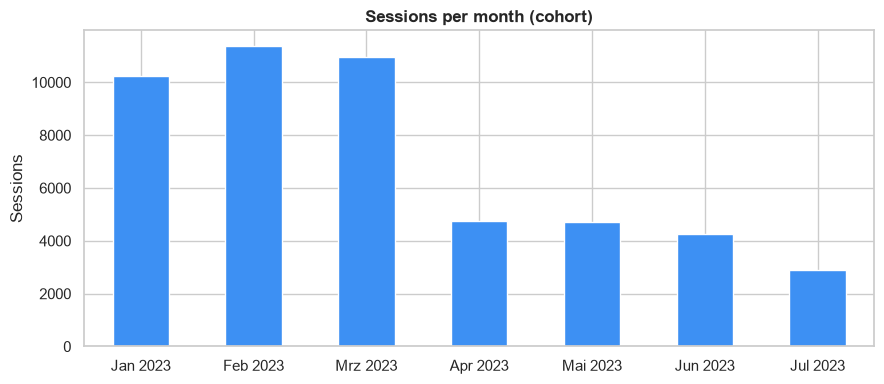

,count,share_%
month,,
2023-01,10245,20.8
2023-02,11394,23.2
2023-03,10956,22.3
2023-04,4762,9.7
2023-05,4704,9.6
2023-06,4257,8.7
2023-07,2893,5.9


Avg sessions per month: Jan–Mar 10,865 | Apr–Jun 4,574 | ratio 2.4x


In [104]:
monthly = df["session_start"].dt.to_period("M").value_counts().sort_index()
monthly.index = monthly.index.strftime("%b %Y") 
ax = monthly.plot(kind="bar", color=PALETTE[0], figsize=(9, 4), rot=0)
ax.set_title("Sessions per month (cohort)", fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("Sessions")
plt.tight_layout(); plt.show()

display(count_share(df["session_start"].dt.to_period("M"), label="month", sort_index=True))
q1 = monthly.iloc[0:3].mean(); q2 = monthly.iloc[3:6].mean()   # Jan–Mar vs Apr–Jun (July is partial)
print(f"Avg sessions per month: Jan–Mar {q1:,.0f} | Apr–Jun {q2:,.0f} | ratio {q1 / q2:.1f}x")

Session volume is more than twice as high in January–March as in April–July (about 10,900 vs 4,600 sessions per month, ratio 2.4×, table above) (July is a partial month, data ends 28 Jul). Part of this is likely seasonal trip planning; part may be how the cohort was built. Behavior is therefore summarized per user over the full window rather than compared month by month.

### 5.2 What happens in a session?

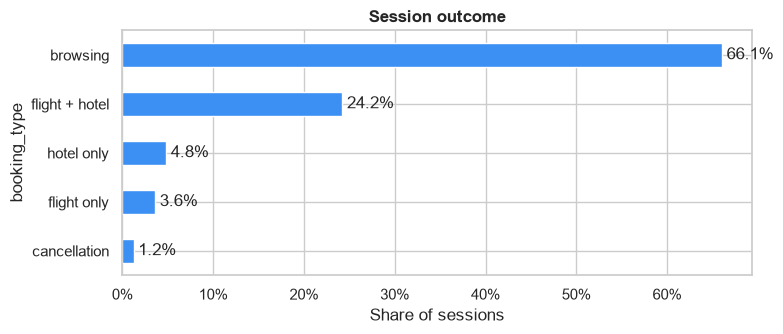

,count,share_%
booking_type,,
browsing,32509,66.1
flight + hotel,11927,24.2
hotel only,2382,4.8
flight only,1783,3.6
cancellation,610,1.2


In [105]:
order = ["browsing", "flight + hotel", "hotel only", "flight only", "cancellation"]
share = df["booking_type"].value_counts(normalize=True).reindex(order) * 100
ax = share.plot(kind="barh", color=PALETTE[0], figsize=(8, 3.5))
ax.invert_yaxis(); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
for i, v in enumerate(share): ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
ax.set_title("Session outcome", fontweight="bold"); ax.set_xlabel("Share of sessions")
plt.tight_layout(); plt.show()

count_share(df["booking_type"]).reindex(order)

About two thirds of all sessions end without a booking (32,509 of 49,211 = 66.1 %). Among bookings, flight + hotel packages dominate (24.2 % of sessions); hotel-only (4.8 %) and flight-only trips (3.6 %) are smaller but distinct groups. Cancellations are rare (610 sessions, 1.2 %).

### 5.3 Who are the customers?

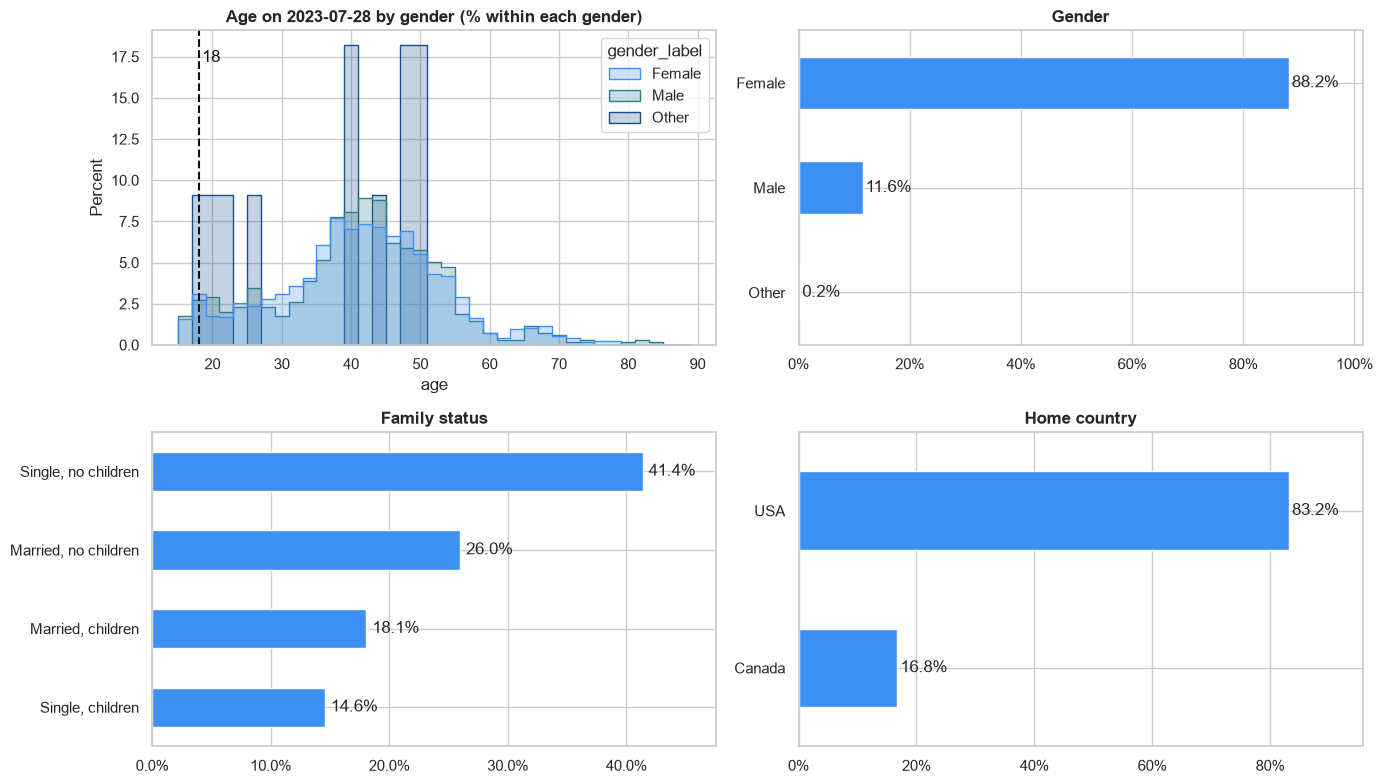

count  share_%
column        value                               
gender_label  Female                 5292     88.2
              Male                    695     11.6
              Other                    11      0.2
family_status Single, no children    2482     41.4
              Married, no children   1558     26.0
              Married, children      1084     18.1
              Single, children        874     14.6
has_children  False                  4040     67.4
              True                   1958     32.6
home_country  USA                    4991     83.2
              Canada                 1007     16.8

,count,mean,std,min,25%,50%,75%,max
gender_label,,,,,,,,
Female,5292.0,40.9,12.1,16.0,34.0,41.0,48.0,88.0
Male,695.0,40.6,11.9,16.0,34.0,41.0,48.0,84.0
Other,11.0,36.5,12.9,17.0,24.0,40.0,47.5,50.0


In [106]:
users["family_status"] = np.select(
    [users["married"] & users["has_children"], users["married"], users["has_children"]],
    ["Married, children", "Married, no children", "Single, children"], default="Single, no children")
users["age_years"] = users["age"].astype(float)
users["gender_label"] = users["gender"].map({"F": "Female", "M": "Male", "O": "Other"})

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
ax = axes[0, 0]
# step outlines + % within each gender, so the small groups are comparable to the large female group
# ("Other" has only 11 users, so its outline is jumpy – too few for a real distribution)
sns.histplot(data=users, x="age_years", hue="gender_label", hue_order=["Female", "Male", "Other"],
             stat="percent", common_norm=False, element="step", alpha=.25, bins=range(15, 90, 2),
             ax=ax, palette=[PALETTE[0], PALETTE[2], PALETTE[3]])
ax.axvline(18, color=PALETTE[4], ls="--"); ax.text(18.5, ax.get_ylim()[1] * .9, "18", color=PALETTE[4])
ax.set_title("Age on 2023-07-28 by gender (% within each gender)", fontweight="bold"); ax.set_xlabel("age")

def share_bar(series, ax, title):
    s = series.value_counts(normalize=True) * 100
    s.plot(kind="barh", ax=ax, color=PALETTE[0]); ax.invert_yaxis(); ax.set_ylabel("")
    ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_title(title, fontweight="bold")
    for i, v in enumerate(s): ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
    ax.set_xlim(0, s.max() * 1.15)

share_bar(users["gender_label"], axes[0, 1], "Gender")
share_bar(users["family_status"], axes[1, 0], "Family status")
share_bar(users["home_country"], axes[1, 1], "Home country")
plt.tight_layout(); plt.show()

# Numbers behind the charts: count and share of all 5,998 users
display(pd.concat({col: count_share(users[col]) for col in ["gender_label", "family_status", "has_children", "home_country"]},
                  names=["column", "value"]))
# Age by gender
users.groupby("gender_label")["age_years"].describe().round(1)

The typical customer is a woman in her mid-30s to late 40s (88 % female, 12 % male, 0.2 % other; middle half of users aged 34–48, median 41); 83 % live in the USA and 17 % in Canada. A third of users have children (1,958 of 5,998 = 32.6 %) – relevant for a separate Family segment. The age distribution looks the same for women and men (median 41 and the same quartiles 34–48 for both); the 11 users with gender *Other* are too few to compare, so gender is described but not used to build segments. *All numbers: tables above.*

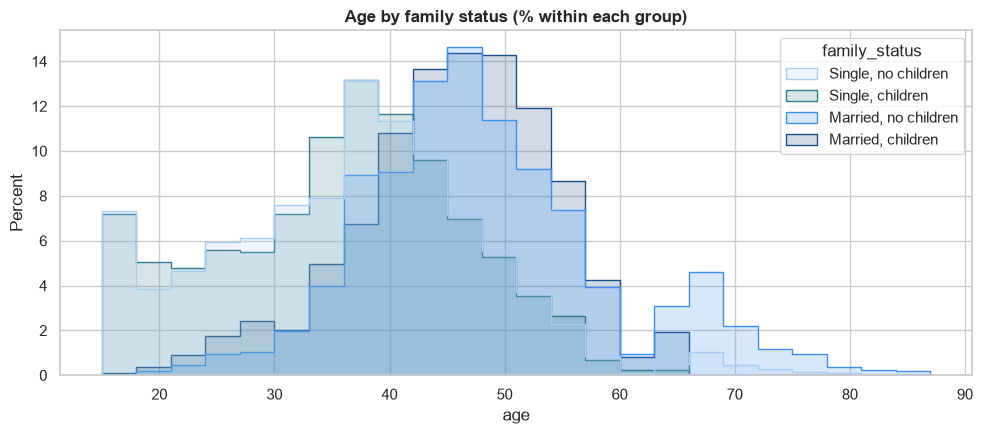

,count,age_q1,age_median,age_q3,share_%
family_status,,,,,
"Single, no children",2482,28.0,37.0,44.0,41.4
"Single, children",874,28.0,36.0,43.0,14.6
"Married, no children",1558,41.0,47.0,54.0,26.0
"Married, children",1084,40.0,46.0,51.0,18.1


In [107]:
# Third dimension: age distribution per family status
fam_order = ["Single, no children", "Single, children", "Married, no children", "Married, children"]
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(data=users, x="age_years", hue="family_status", hue_order=fam_order,
             stat="percent", common_norm=False, element="step", alpha=.2, bins=range(15, 90, 3),
             ax=ax, palette=[PALETTE[1], PALETTE[2], PALETTE[0], PALETTE[3]])
ax.set_title("Age by family status (% within each group)", fontweight="bold"); ax.set_xlabel("age")
plt.tight_layout(); plt.show()

age_by_fam = users.groupby("family_status")["age_years"].describe()[["count", "25%", "50%", "75%"]].reindex(fam_order)
age_by_fam["share_%"] = (age_by_fam["count"] / len(users) * 100).round(1)
age_by_fam.rename(columns={"25%": "age_q1", "50%": "age_median", "75%": "age_q3"}).astype({"count": int})

**Age by family status:** married users are about 10 years older than single users (median 46–47 vs 36–37), with or without children. Family status and age overlap, which helps to *describe* segments later (e.g. Family Crew vs Couples & Friends). *Numbers: table above.*

### 5.4 Who travels with whom? (party size and luggage)

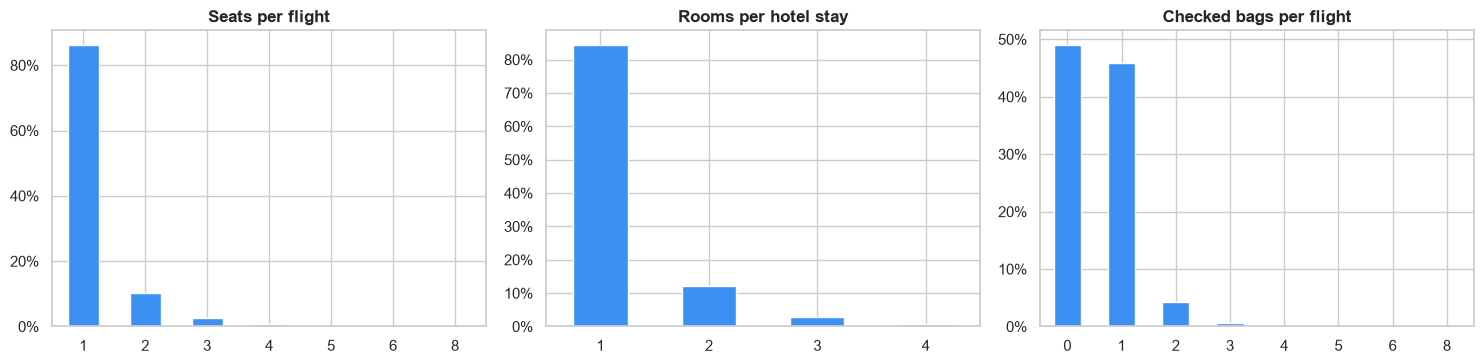

Flights with 2+ seats: 1,800 of 13,157 (13.7%)
Hotel stays with 2+ rooms: 2,153 of 13,896 (15.5%)


,seats,rooms,checked_bags
No children,1.17,1.19,0.56
Has children,1.2,1.2,0.6


In [108]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, title in zip(axes, ["seats", "rooms", "checked_bags"], ["Seats per flight", "Rooms per hotel stay", "Checked bags per flight"]):
    s = bookings[col].dropna().astype(int).value_counts(normalize=True).sort_index() * 100
    s.plot(kind="bar", ax=ax, color=PALETTE[0]); ax.set_title(title, fontweight="bold")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

party = bookings.groupby("has_children")[["seats", "rooms", "checked_bags"]].mean().round(2)
party.index = ["No children", "Has children"]

for col, label in [("seats", "Flights with 2+ seats"), ("rooms", "Hotel stays with 2+ rooms")]:
    s = bookings[col].dropna()
    print(f"{label}: {(s >= 2).sum():,} of {len(s):,} ({(s >= 2).mean():.1%})")
party

Most trips are for one person with one room and at most one bag – about 14 % of flights have 2+ seats (1,800 of 13,157) and 15 % of hotel stays 2+ rooms (2,153 of 13,896) (printed above).

**Surprise:** users with children book almost the same party size as users without (1.20 vs 1.17 seats). `has_children` alone does **not** mean family travel – many parents travel alone. That's why the Family Crew rule needs both: children **and** 2+ seats or rooms on average.

### 5.5 When and how long? (weekend vs weekday, trip length)

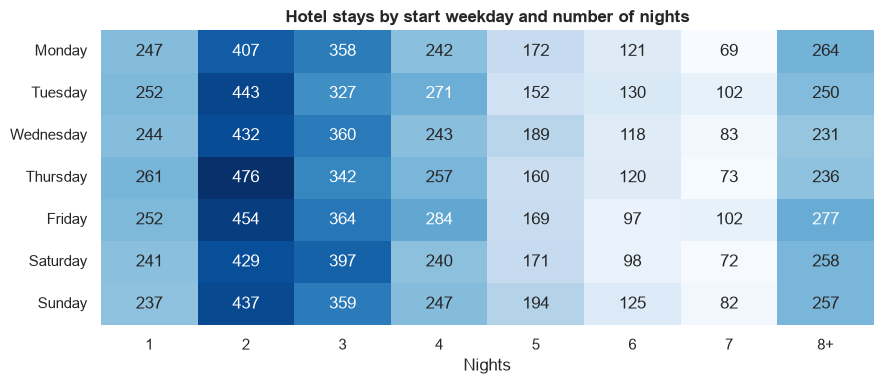

,count,share_%
start weekday,,
Monday,2143,13.8
Tuesday,2201,14.2
Wednesday,2220,14.3
Thursday,2244,14.5
Friday,2262,14.6
Saturday,2187,14.1
Sunday,2232,14.4


Trips starting Fri/Sat: 4,449 of 15,489 (28.7%) | median nights: 3.0


In [109]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = (bookings.dropna(subset=["nights_calc"])
        .assign(nights=lambda d: d["nights_calc"].astype(int).clip(upper=8).astype(str).replace("8", "8+"))
        .pivot_table(index="start_weekday", columns="nights", values="trip_id", aggfunc="count")
        .reindex(days))
heat = heat[[c for c in [str(i) for i in range(1, 8)] + ["8+"] if c in heat.columns]]
plt.figure(figsize=(9, 4))
sns.heatmap(heat, cmap="Blues", annot=True, fmt=".0f", cbar=False)
plt.title("Hotel stays by start weekday and number of nights", fontweight="bold"); plt.xlabel("Nights"); plt.ylabel("")
plt.tight_layout(); plt.show()
display(count_share(bookings["start_weekday"], label="start weekday").reindex(days))
print(f"Trips starting Fri/Sat: {bookings['weekend_start'].sum():,.0f} of {bookings['weekend_start'].notna().sum():,} "
      f"({bookings['weekend_start'].mean():.1%}) | median nights: {bookings['nights_calc'].median()}")

Short stays of 1–3 nights dominate. Every weekday gets about 14 % of trip starts (table above). Overall, 28.7 % of trips start on a Friday or Saturday – exactly what you'd expect by chance (2 of 7 days = 28.6 %), so there is no general weekend bias. Weekend Escapers are therefore defined at **user** level: users whose own Fri/Sat share is clearly higher (≥ 50 %) and whose stays are short.

### 5.6 How far? (distance)

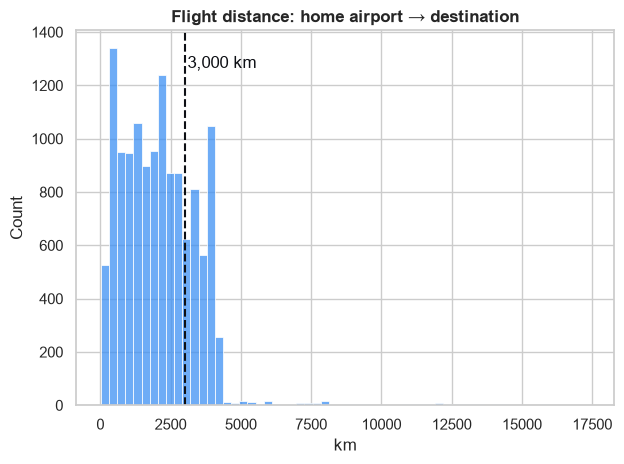

Median distance: 2,001 km | flights over 3,000 km: 3,348 of 13,157 (25.4%)


In [110]:
ax = sns.histplot(bookings["distance_km"].dropna(), bins=60, color=PALETTE[0])
ax.axvline(3000, color=PALETTE[4], ls="--"); ax.text(3100, ax.get_ylim()[1] * .9, "3,000 km", color=PALETTE[4])
ax.set_title("Flight distance: home airport → destination", fontweight="bold"); ax.set_xlabel("km")
plt.tight_layout(); plt.show()
dist = bookings["distance_km"].dropna()
print(f"Median distance: {dist.median():,.0f} km | flights over 3,000 km: {(dist > 3000).sum():,} of {len(dist):,} ({(dist > 3000).mean():.1%})")

Most flights are domestic or cross-border (median about 2,000 km). A long tail of long-haul trips (> 3,000 km: 3,348 of 13,157 flights = 25.4 %) – together with checked bags – defines the Long-haul Packers.

### 5.7 Where do customers live and travel? (maps)

Interactive maps (zoom and hover in Colab / VS Code). *GitHub does not display Plotly charts – the same maps are rebuilt in Tableau for the presentation.*

In [111]:
import plotly.express as px

def show_map(fig):
    try:
        fig.show()
    except ValueError as err:   # nbformat missing in this Python → see the install step in 1 (restart the kernel once)
        print("Map not shown:", str(err).splitlines()[0])

# group by city AND airport: "Portland" exists twice (PDX Oregon, PWM Maine)
home = (users.groupby(["home_city", "home_airport", "home_airport_lat", "home_airport_lon"]).size()
        .reset_index(name="users"))
home["label"] = home["home_city"] + " (" + home["home_airport"] + ")"
fig = px.scatter_geo(home, lat="home_airport_lat", lon="home_airport_lon", size="users", hover_name="label",
                     scope="north america", title="Where cohort users live (home airports)",
                     color_discrete_sequence=[PALETTE[0]], size_max=30, width=900, height=500)
show_map(fig)

dest = (bookings.dropna(subset=["destination"])
        .groupby(["destination", "destination_airport_lat", "destination_airport_lon"]).size()
        .reset_index(name="trips"))
fig = px.scatter_geo(dest, lat="destination_airport_lat", lon="destination_airport_lon", size="trips", hover_name="destination",
                     projection="natural earth", title="Where they fly to (valid bookings)",
                     color_discrete_sequence=[PALETTE[2]], size_max=30, width=900, height=500)
show_map(fig)

dest["share_%"] = (dest["trips"] / dest["trips"].sum() * 100).round(1)
print(f"Top 10 destinations ({dest['trips'].sum():,} trips with a destination):")
dest.sort_values("trips", ascending=False).head(10)[["destination", "trips", "share_%"]].reset_index(drop=True)

Top 10 destinations (13,157 trips with a destination):


,destination,trips,share_%
0,New York,1899,14.4
1,Los Angeles,993,7.5
2,Toronto,708,5.4
3,Chicago,687,5.2
4,Houston,550,4.2
5,Montreal,437,3.3
6,Phoenix,412,3.1
7,Philadelphia,387,2.9
8,San Antonio,361,2.7
9,Dallas,354,2.7


Customers come from big US and Canadian cities; most trips go to other North American cities (New York, Los Angeles, Toronto …), with a smaller set of international long-haul destinations – the long tail seen in the distance chart.

### 5.8 How much do trips cost?

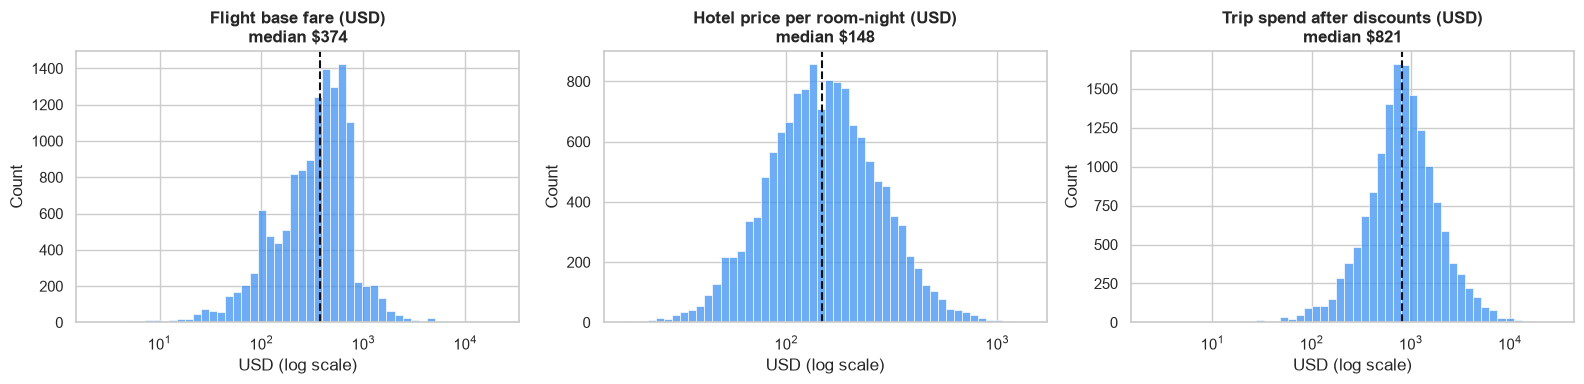

In [112]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(axes, ["base_fare_usd", "hotel_per_room_usd", "trip_spend_usd"],
                          ["Flight base fare (USD)", "Hotel price per room-night (USD)", "Trip spend after discounts (USD)"]):
    s = bookings[col].dropna()
    s = s[s > 0]
    sns.histplot(s, bins=50, log_scale=True, ax=ax, color=PALETTE[0])
    ax.axvline(s.median(), color=PALETTE[4], ls="--")
    ax.set_title(f"{title}\nmedian ${s.median():,.0f}", fontweight="bold"); ax.set_xlabel("USD (log scale)")
plt.tight_layout(); plt.show()

Prices are strongly right-skewed (log scale): most trips are mid-priced, a small share are premium. This supports keeping outliers and log-transforming spend before clustering.

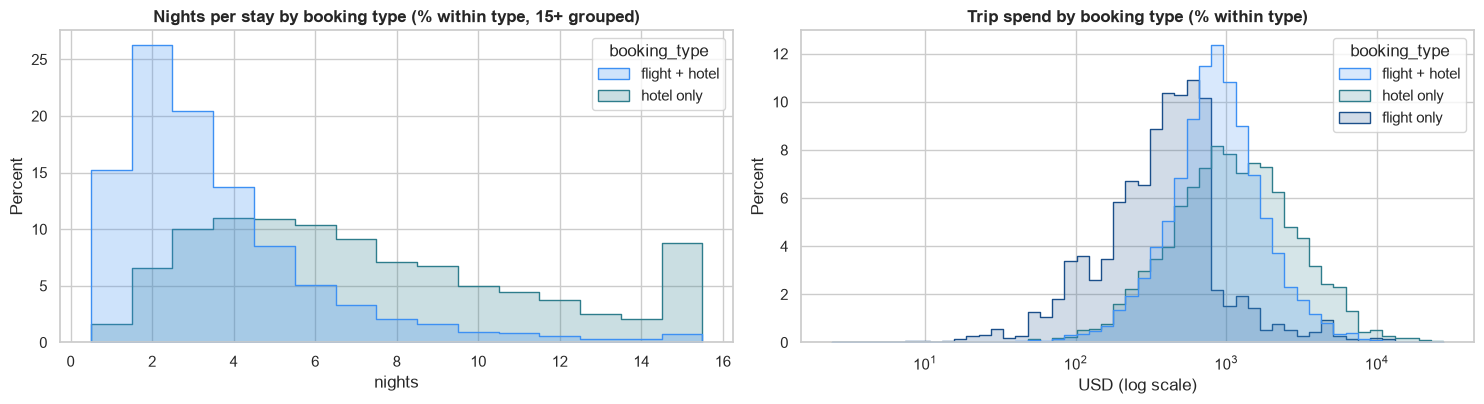

,trips,share_%,median_nights,median_spend_usd
booking_type,,,,
flight + hotel,11564,74.7,3.0,855.7
hotel only,2332,15.1,6.0,1093.2
flight only,1593,10.3,<NA>,393.0


In [113]:
# Third dimension: trip length and spend per booking type
types = ["flight + hotel", "hotel only", "flight only"]
type_colors = dict(zip(types, [PALETTE[0], PALETTE[2], PALETTE[3]]))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))

stays = bookings[bookings["booking_type"].isin(types[:2])].dropna(subset=["nights_calc"])
sns.histplot(data=stays.assign(nights=stays["nights_calc"].astype(float).clip(upper=15)), x="nights",
             hue="booking_type", hue_order=types[:2], stat="percent", common_norm=False, element="step",
             alpha=.25, discrete=True, ax=axes[0], palette=type_colors)
axes[0].set_title("Nights per stay by booking type (% within type, 15+ grouped)", fontweight="bold")

spend = bookings[bookings["trip_spend_usd"] > 0]
sns.histplot(data=spend, x="trip_spend_usd", hue="booking_type", hue_order=types, stat="percent", common_norm=False,
             element="step", alpha=.2, bins=50, log_scale=True, ax=axes[1], palette=type_colors)
axes[1].set_title("Trip spend by booking type (% within type)", fontweight="bold"); axes[1].set_xlabel("USD (log scale)")
plt.tight_layout(); plt.show()

by_type = bookings.groupby("booking_type").agg(trips=("trip_id", "count"),
                                              median_nights=("nights_calc", "median"),
                                              median_spend_usd=("trip_spend_usd", "median")).reindex(types)
by_type.insert(1, "share_%", (by_type["trips"] / by_type["trips"].sum() * 100).round(1))
by_type

**By booking type:** hotel-only trips are clearly different from packages – they last longer (median 6 vs 3 nights) and cost more per trip, while flight-only trips are the cheapest. This supports a separate **Hotel Stayers** segment. *Numbers: table above.*

### 5.9 Discounts

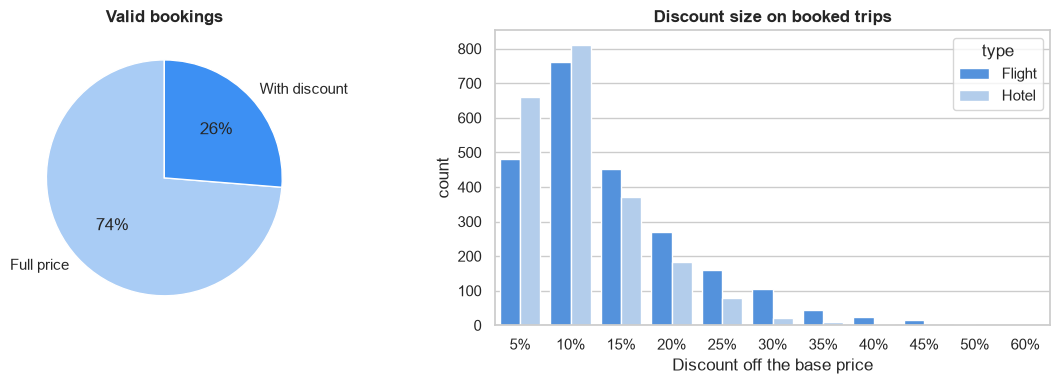

,count,share_%
valid bookings,,
Full price,11420,73.7
With discount,4069,26.3


type,Flight,Hotel,share_%
discount size,,,
5%,481,660,25.6
10%,760,812,35.3
15%,451,370,18.4
20%,270,182,10.2
25%,159,80,5.4
30%,104,22,2.8
35%,43,10,1.2
40%,23,4,0.6
45%,14,2,0.4


In [114]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bookings["discount_used"].map({True: "With discount", False: "Full price"}).value_counts().plot(
    kind="pie", autopct="%1.0f%%", ax=axes[0], colors=[PALETTE[1], PALETTE[0]], startangle=90)
axes[0].set_ylabel(""); axes[0].set_title("Valid bookings", fontweight="bold")
disc = pd.concat([bookings["flight_discount_amount"].dropna().rename("Flight"), bookings["hotel_discount_amount"].dropna().rename("Hotel")], axis=1)
disc_long = disc.melt(var_name="type", value_name="discount").dropna()
disc_long["discount"] = (disc_long["discount"].round(2) * 100).astype(int)
disc_long["label"] = disc_long["discount"].astype(str) + "%"
label_order = [f"{d}%" for d in sorted(disc_long["discount"].unique())]
sns.countplot(data=disc_long, x="label", hue="type", order=label_order, ax=axes[1])
axes[1].set_title("Discount size on booked trips", fontweight="bold"); axes[1].set_xlabel("Discount off the base price")
plt.tight_layout(); plt.show()

display(count_share(bookings["discount_used"].map({True: "With discount", False: "Full price"}), label="valid bookings"))
size_tbl = pd.crosstab(disc_long["discount"], disc_long["type"])
size_tbl["share_%"] = (size_tbl.sum(axis=1) / size_tbl.values.sum() * 100).round(1)
size_tbl.index = [f"{d}%" for d in size_tbl.index]
size_tbl.rename_axis("discount size")

Roughly a quarter of bookings use a discount (4,069 of 15,489 = 26.3 %), mostly 5–20 % (together about 90 % of all discounts). Most bookings are at full price (73.7 %) – so an exclusive-discount perk should target the users who **consistently** book discounted trips (Deal Hunters), not everyone.

### 5.10 Flat signals – what *not* to segment on

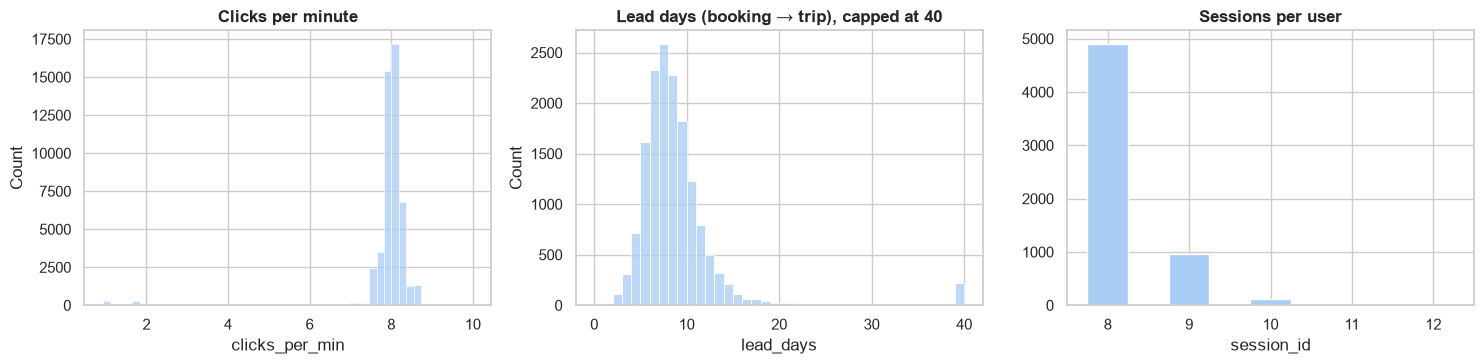

count    49211.00
mean         7.95
std          0.78
min          0.93
25%          7.89
50%          8.04
75%          8.17
max         10.00

Lead days median: 8.0 | 90th percentile: 12.0


,count,share_%
sessions per user,,
8,4909,81.8
9,961,16.0
10,119,2.0
11,8,0.1
12,1,0.0


In [115]:
df["clicks_per_min"] = df["page_clicks"] / df["session_minutes"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(df["clicks_per_min"], bins=50, ax=axes[0], color=PALETTE[1]); axes[0].set_title("Clicks per minute", fontweight="bold")
sns.histplot(bookings["lead_days"].clip(upper=40), bins=40, ax=axes[1], color=PALETTE[1]); axes[1].set_title("Lead days (booking → trip), capped at 40", fontweight="bold")
df.groupby("user_id")["session_id"].count().value_counts().sort_index().plot(kind="bar", ax=axes[2], color=PALETTE[1])
axes[2].set_title("Sessions per user", fontweight="bold"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
print(df["clicks_per_min"].describe().round(2).to_string())
print("\nLead days median:", bookings["lead_days"].median(), "| 90th percentile:", bookings["lead_days"].quantile(.9))
df = df.drop(columns="clicks_per_min")
count_share(df.groupby("user_id")["session_id"].count(), label="sessions per user", sort_index=True)

- **Clicks per minute** is almost constant (~8 for everyone) → clicks and session length measure the same thing.
- **Lead time** is short for nearly everyone (median 8 days, 90 % within 12 days) → early planners vs last-minute bookers can't be separated.
- **Sessions per user** is 8 for most users (82 %, table above) because of the cohort rule.

These signals are documented but **not used** as segmentation features.

### 5.11 Correlation of trip features

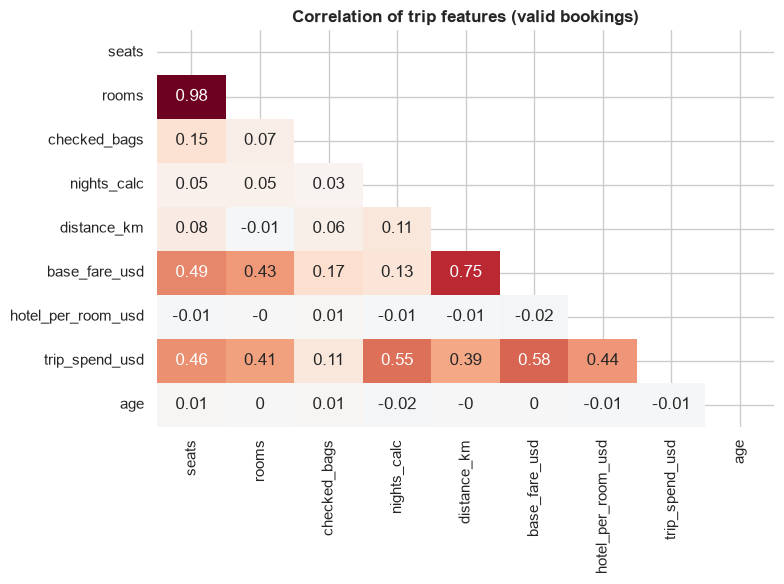

In [116]:
corr_cols = ["seats", "rooms", "checked_bags", "nights_calc", "distance_km", "base_fare_usd", "hotel_per_room_usd", "trip_spend_usd", "age"]
corr = bookings[corr_cols].astype(float).corr().round(2)
plt.figure(figsize=(8, 6))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1, cbar=False)
plt.title("Correlation of trip features (valid bookings)", fontweight="bold"); plt.tight_layout(); plt.show()

- **Seats and rooms are almost the same signal (r = 0.98)** → in clustering, use one combined party-size feature instead of both, otherwise party size counts twice.
- Spend is driven by nights (0.55), fare (0.58) and party size; distance mainly works through the fare.
- Checked bags are only weakly linked to party size (0.15) → luggage is its own behavior (Long-haul Packers).
- **Age is unrelated to every trip feature (|r| ≤ 0.02)** → segment on **behavior**, and use demographics to describe the segments afterwards.

## 6 – Export & Key Findings

In [117]:
# Save next to the input data (local data folder); only create "data/" if no local folder exists yet
OUTPUT_DIR = DATA_DIR if DATA_DIR is not None else Path("data")
OUTPUT_DIR.mkdir(exist_ok=True)
df.to_csv(OUTPUT_DIR / "sessions_clean.csv", index=False)
print("Saved:", (OUTPUT_DIR / "sessions_clean.csv").resolve(), "|", df.shape)
df.dtypes.to_frame("dtype").T

Saved: C:\Users\jackl\OneDrive\Attachments\Desktop\Masterschool\Mastery Project\TravelTide\data\sessions_clean.csv | (49211, 59)


,session_id,user_id,trip_id,session_start,session_end,page_clicks,flight_discount,flight_discount_amount,flight_booked,hotel_discount,hotel_discount_amount,hotel_booked,cancellation,session_count,gender,married,has_children,home_country,home_city,home_airport,home_airport_lat,home_airport_lon,origin_airport,destination,destination_airport,seats,return_flight_booked,departure_time,return_time,checked_bags,trip_airline,destination_airport_lat,destination_airport_lon,base_fare_usd,hotel_name,rooms,check_in_time,check_out_time,hotel_per_room_usd,hotel_city,home_airport_name,destination_airport_name,invalid_hotel_dates,nights_calc,trip_cancelled,valid_booking,age,tenure_months,is_minor,session_minutes,booking_type,trip_start,start_weekday,weekend_start,lead_days,trip_city,distance_km,discount_used,trip_spend_usd
dtype,str,int64,str,datetime64[us],datetime64[us],int64,bool,float64,bool,bool,float64,bool,bool,int64,str,bool,bool,str,str,str,float64,float64,str,str,str,Int64,boolean,datetime64[us],datetime64[us],Int64,str,float64,float64,float64,str,Int64,datetime64[us],datetime64[us],float64,object,str,str,bool,Int64,bool,bool,Int64,float64,boolean,float64,str,datetime64[us],str,object,float64,str,float64,object,float64


If you worked from a local folder that is not synced with Google Drive, upload `sessions_clean.csv` to the Drive `data` folder so Part 2 and Tableau use the same cleaned data.

### Key findings
1. **Cohort:** 49,211 sessions from 5,998 users (Jan 4 – Jul 28, 2023); 88 % of users are female, 83 % live in the USA (3.3, 5.3).
2. **Most sessions are browsing:** about two thirds of sessions end without a booking (66.1 %, 5.2); 556 of 5,998 users (9.3 %, 3.6) never kept a booking → a dedicated *Dreamers* segment.
3. **Data quality fixed, no rows dropped:** hotel nights recalculated from dates (raw values count 24-hour periods), 2.9 % invalid hotel dates flagged (3.5), 610 cancelled trips excluded from travel behavior, 246 under-18 users flagged (4.1 %, 3.7).
4. **Strong behavioral signals:** party size (seats ≈ rooms), checked bags, trip length, distance, discount use (26.3 % of bookings, 5.9) and hotel-only trips (longer and pricier, 5.8). Having children or being a certain age does **not** predict trip behavior on its own.
5. **Flat signals:** clicks per minute, lead time and sessions per user barely vary → not used for segmentation.

**Next:** Part 2 builds one row per user from these columns (`user_base` from SQL, checked against this table) and defines the segments.